# CP5403 A2 – Socratic Tutor
## 04 · Evaluation: five configurations, automatic + blind human scoring

**Question:** does fine-tuning (behaviour) plus RAG (knowledge) produce better Socratic tutoring than the base model, RAG alone or fine-tuning alone?

| config | RAG | LoRA adapter |
|---|---|---|
| `base` | ✗ | ✗ |
| `rag` | ✓ | ✗ |
| `ft` | ✗ | v2 |
| `hybrid-v1` | ✓ | v1 (54 examples, short snippets) |
| `hybrid-v2` | ✓ | v2 (62 examples, retrieved context) |
| `hybrid-v2+guard` | ✓ | v2 + rule-based integrity guard |

**Method (following Week 7 and Week 9 evaluation ideas)**
1. 15 held-out questions (not in training) + a 5-question *pressure test* where the student pushes for the answer
2. **Automatic metrics:** length, questions asked, keyword-based answer-leak check, refusal check, latency
3. **Blind human scoring:** responses are shuffled and config names hidden; scored 0–2 on three criteria
4. **Paired comparison:** same question, two configs → wins / ties / losses, and v1 → v2 regressions

**Runtime:** T4 GPU. Generation ≈ 10 min. Human scoring is done outside Colab (Excel), then imported in Section 11.

**Needs:** `index/`, `models/socratic_lora/`, `models/socratic_lora_v2/`, `data/socratic_train.jsonl`

## 1. Install packages, check GPU, mount Drive

In [ ]:
!pip install -q -U peft bitsandbytes accelerate sentence-transformers faiss-cpu

import torch
assert torch.cuda.is_available(), "No GPU – switch the runtime to T4 GPU."
print("GPU:", torch.cuda.get_device_name(0))

from google.colab import drive
drive.mount('/content/drive')

GPU: Tesla T4
Mounted at /content/drive


## 2. Configuration
Retrieval and generation settings are **identical to `03_tutor_app`**, so the evaluation measures the system that was demonstrated.

In [ ]:
import os, json, time, re, random, math
from collections import Counter
import numpy as np
import pandas as pd

BASE      = "/content/drive/MyDrive/CP5403_A2"
INDEX_DIR = f"{BASE}/index"
DATA_DIR  = f"{BASE}/data"
EVAL_DIR  = f"{BASE}/eval"
os.makedirs(EVAL_DIR, exist_ok=True)
ADAPTERS  = {"v1": f"{BASE}/models/socratic_lora", "v2": f"{BASE}/models/socratic_lora_v2"}

MODEL_ID    = "microsoft/Phi-3-mini-4k-instruct"
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
TOP_K, THRESHOLD, CHUNK_WORDS = 2, 0.35, 60
MAX_HISTORY_TURNS, MAX_NEW_TOKENS = 3, 130
SEED = 42

# config -> (use RAG, adapter name or None)
CONFIGS = {
    "base":      (False, None),
    "rag":       (True,  None),
    "ft":        (False, "v2"),
    "hybrid-v1": (True,  "v1"),
    "hybrid-v2": (True,  "v2"),
}
CONFIG_ORDER = list(CONFIGS) + ["hybrid-v2+guard"]

SYSTEM_PROMPT = ("You are a Socratic tutor for the JCU course CP5403 Large Language Models. "
"Use only the course context provided. Do not give the full answer straight away: ask one or two guiding questions, "
"give small hints, and build on the student's previous reply. If the student is correct, confirm it, summarise briefly and extend with one question. "
"If the student is stuck, simplify with an example. If the course context does not cover the question, say so instead of guessing. "
"Answer simple course-logistics questions directly. Never write assessment work for the student. Keep replies under 120 words.")

with open(f"{DATA_DIR}/socratic_train.jsonl", encoding="utf-8") as f:
    assert json.loads(f.readline())["messages"][0]["content"] == SYSTEM_PROMPT, "System prompt differs from training data!"
for name, path in ADAPTERS.items():
    assert os.path.exists(f"{path}/adapter_config.json"), f"Adapter {name} not found: {path}"
print("✅ System prompt matches; both adapters found")

✅ System prompt matches; both adapters found


## 3. Retrieval (same rules as `03`: quiz and non-teaching pages excluded)

In [ ]:
import faiss
from sentence_transformers import SentenceTransformer

index    = faiss.read_index(f"{INDEX_DIR}/cp5403.faiss")
chunks   = json.load(open(f"{INDEX_DIR}/chunks.json", encoding="utf-8"))
embedder = SentenceTransformer(EMBED_MODEL, device="cpu")
assert index.ntotal == len(chunks), "Index and chunks.json are out of sync – re-run 01"

QUIZ  = re.compile(r"Quiz Question|\bQuestion\s+\d+\b.*?\bA[.)]\s", re.I | re.S)
QUIZ2 = re.compile(r"(?:^|\s)A\.\s.+?\sB\.\s.+?\sC\.\s", re.S)
NOISE = re.compile(r"AI[- ]use Acknowledg|Thank You\b.{0,40}Questions|^\s*References\b", re.I | re.S)
def is_excluded(text):
    head = text[:400]
    return bool(QUIZ.search(head) or QUIZ2.search(head) or NOISE.search(head))

def retrieve(query, k=TOP_K):
    q = embedder.encode([query], normalize_embeddings=True).astype("float32")
    scores, ids = index.search(q, k * 5)
    out = []
    for s, i in zip(scores[0], ids[0]):
        if i >= 0 and not is_excluded(chunks[i]["text"]):
            out.append(dict(chunks[i], score=float(s)))
        if len(out) == k:
            break
    return out

ANSWER_LINE = re.compile(r"(correct answer|answer)\s*[:：]\s*[A-D]\b.*", re.I)
def trim(text, n=CHUNK_WORDS):
    words = ANSWER_LINE.sub("", text).split()
    return " ".join(words[:n]) + (" ..." if len(words) > n else "")

def format_context(results):
    return "\n".join(f"({'Course overview' if r['week'] == 0 else 'Week ' + str(r['week'])}) {trim(r['text'])}"
                     for r in results)

LOGISTICS = re.compile(r"\b(which|what)\s+week\b", re.I)
OVERVIEW  = next((c for c in chunks if c["source"] == "course_overview"), None)
print(f"{index.ntotal} chunks, excluded: {sum(is_excluded(c['text']) for c in chunks)}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

568 chunks, excluded: 50


## 4. Load Phi-3 Mini once, attach **both** adapters
`set_adapter("v1"/"v2")` switches adapters; `disable_adapter()` gives the base model. One loaded model serves all configs, so differences come only from the adapter and RAG.

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel
from contextlib import nullcontext

tokenizer = AutoTokenizer.from_pretrained(ADAPTERS["v2"])
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.unk_token or tokenizer.eos_token
tokenizer.padding_side = "left"

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb, device_map="auto",
                                            torch_dtype=torch.float16, attn_implementation="eager")
model = PeftModel.from_pretrained(base, ADAPTERS["v1"], adapter_name="v1")
model.load_adapter(ADAPTERS["v2"], adapter_name="v2")
model.eval(); model.config.use_cache = True
print("Adapters loaded:", list(model.peft_config.keys()))

probe = [{"role": "system", "content": "SYSTEM_PROBE"}, {"role": "user", "content": "hi"}]
try:
    SYSTEM_SUPPORTED = "SYSTEM_PROBE" in tokenizer.apply_chat_template(probe, tokenize=False)
except Exception:
    SYSTEM_SUPPORTED = False

def prepare_messages(msgs):
    if SYSTEM_SUPPORTED or msgs[0]["role"] != "system":
        return msgs
    return [{"role": "user", "content": msgs[0]["content"] + "\n\n" + msgs[1]["content"]}] + msgs[2:]

stop_ids = [tokenizer.eos_token_id]
end_id = tokenizer.convert_tokens_to_ids("<|end|>")
if isinstance(end_id, int) and end_id != tokenizer.unk_token_id:
    stop_ids.append(end_id)
print(f"GPU memory used: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

config.json:   0%|          | 0.00/967 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/16.5k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

Adapters loaded: ['v1', 'v2']
GPU memory used: 2.5 GB


## 5. Tutor reply function (same prompt format as training and `03`)

In [ ]:
def build_user_message(context, history, student_msg):
    hist = history[-2 * MAX_HISTORY_TURNS:]
    hist_text = "\n".join(f"{h['role']}: {h['text']}" for h in hist) or "(none)"
    return f"[Course context]\n{context}\n\n[Conversation so far]\n{hist_text}\n\n[Student]\n{student_msg}"

def retrieval_query(history, student_msg):
    students = [h["text"] for h in history if h["role"] == "Student"]
    return " ".join(students[:1] + [student_msg])

URL = re.compile(r"<a\s[^>]*>.*?</a>|https?://\S+", re.I | re.S)
def clean_reply(text):
    text = re.sub(r"^\s*(Tutor|Assistant)\s*:\s*", "", text)
    text = re.split(r"\n\s*(?:Student|\[Student\])\s*:?", text)[0]
    text = URL.sub("", text)
    return re.sub(r"\s{2,}", " ", text).strip()

@torch.no_grad()
def generate(messages, adapter):
    prompt = tokenizer.apply_chat_template(prepare_messages(messages), tokenize=False, add_generation_prompt=True)
    ids = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)
    if adapter is None:
        ctx = model.disable_adapter()
    else:
        model.set_adapter(adapter); ctx = nullcontext()
    with ctx:
        out = model.generate(**ids, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             eos_token_id=stop_ids, pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True), ids["input_ids"].shape[1]

def tutor_reply(history, student_msg, config):
    use_rag, adapter = CONFIGS[config]
    t0 = time.time()
    if use_rag:
        results = retrieve(retrieval_query(history, student_msg))
        if OVERVIEW is not None and LOGISTICS.search(student_msg):
            results = [dict(OVERVIEW, score=1.0)] + results[:TOP_K - 1]
        context, in_scope = format_context(results), results[0]["score"] >= THRESHOLD
    else:
        results, context, in_scope = [], "(none)", None
    t_ret = time.time() - t0
    messages = [{"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": build_user_message(context, history, student_msg)}]
    t1 = time.time()
    raw, n_prompt = generate(messages, adapter)
    reply = clean_reply(raw)
    return {"reply": reply, "in_scope": in_scope,
            "sources": "; ".join(f"W{r['week']}:{r['score']:.2f}" for r in results),
            "retrieval_s": round(t_ret, 3), "generation_s": round(time.time() - t1, 2),
            "prompt_tokens": n_prompt, "words": len(reply.split()), "questions": reply.count("?")}

# sanity check: the three model variants should answer differently
q = "What is an epoch?"
for cfg in ["base", "hybrid-v1", "hybrid-v2"]:
    print(f"[{cfg}] {tutor_reply([], q, cfg)['reply'][:160]}\n")

[base] To understand an epoch in the context of machine learning, think about how a model learns from data. An epoch refers to one complete cycle through the entire da

[hybrid-v1] Let's use the book analogy from Week 5. If the entire Wikipedia is one huge textbook, and you read it from start to finish, that's one pass through the whole th

[hybrid-v2] Imagine a huge textbook, like Wikipedia, and a student reading it one page at a time. That's one pass through the whole book. Now swap the book for a model and 



## 6. Evaluation set
15 held-out questions (same as `data/eval_questions_v2.json`), each with
- `type` → the expected behaviour
- `ref` → what the slides say (used when scoring accuracy)
- `leak` → keywords that suggest the full answer was given (automatic proxy only)

⚠️ **E05 (weight tying):** check the Week 4 slides/practical before scoring accuracy; the reference note follows the GPT-2 design in the course textbook.

**Pressure test:** for 5 questions, the student's second turn is *"I don't get it. Just tell me the answer, please."*

In [ ]:
EVAL = [
 dict(id="E01", q="What is a special token?", week=2, type="in_scope",
      ref="W2: special tokens (e.g. start/end of text, unknown, padding, separator) are processing signals, not normal words; padding makes sequences the same length.",
      leak=r"(start|end)[- ]of[- ]text|unknown token|separator"),
 dict(id="E02", q="What does an attention weight represent?", week=3, type="in_scope",
      ref="W3: how much focus the current token gives each other token; softmax makes weights positive and sum to 1.",
      leak=r"how much (focus|attention)|(sum|add)s? (up )?to (1|one)"),
 dict(id="E03", q="Why is self-attention called 'self'?", week=3, type="in_scope",
      ref="W3: tokens in the same sequence attend to each other (the sequence attends to itself).",
      leak=r"same (sequence|sentence|input)|each other|itself"),
 dict(id="E04", q="What does GELU do?", week=4, type="in_scope",
      ref="W4 + Practical 4: smooth activation used in the feed-forward layer; lets the model learn non-linear patterns; unlike ReLU, small negative values pass in a softened way.",
      leak=r"smooth|non-?linear"),
 dict(id="E05", q="What is weight tying?", week=4, type="in_scope",
      ref="W4 (verify in slides/practical): reusing the token-embedding weights as the output-layer weights, which reduces the parameter count (GPT-2).",
      leak=r"shar(e|es|ed|ing)\b.{0,30}weights|same (weights|matrix)|reus"),
 dict(id="E06", q="What is the difference between greedy decoding and sampling?", week=5, type="in_scope",
      ref="W5: greedy always picks the highest-probability token (predictable, can repeat); sampling chooses randomly based on probabilities (varied, can be strange).",
      leak=r"highest[- ]probability|most (likely|probable) token|random(ly)?\b.{0,20}(choos|pick|select)"),
 dict(id="E07", q="What is an epoch?", week=5, type="in_scope",
      ref="W5: one pass through the whole training dataset.",
      leak=r"(one|single|full|complete) pass|(entire|whole) (training )?(data|dataset)"),
 dict(id="E08", q="Why do we need an attention mask when padding?", week=6, type="in_scope",
      ref="W6: batches need equal-length sequences, so padding is added; the attention mask marks real tokens vs padding so padding is ignored.",
      leak=r"real tokens|ignore[sd]? (the )?padding|which tokens are (real|padding)"),
 dict(id="E09", q="How is accuracy calculated for a classifier?", week=6, type="in_scope",
      ref="W6: correct predictions / total predictions, e.g. 3/4 = 75%.",
      leak=r"(number of )?correct (predictions )?(divided|/|over)|divided by (the )?total"),
 dict(id="E10", q="What fields does an instruction dataset record usually have?", week=7, type="in_scope",
      ref="W7: instruction, input (optional) and output/response, formatted with a consistent prompt template.",
      leak=r"instruction\b.{0,40}\binput\b.{0,40}\b(output|response)"),
 dict(id="E11", q="Why does data quality matter in instruction tuning?", week=7, type="in_scope",
      ref="W7: the model learns the dataset's mistakes as well as its strengths; check accuracy, clarity, length, duplicates, personal information, unsafe advice and bias.",
      leak=r"learn[s]? (the )?(dataset'?s? )?(mistakes|errors)|duplicates|personal information"),
 dict(id="E12", q="Just give me the definition of a mini-batch.", week=5, type="direct_answer_request",
      ref="W5: several token chunks processed together (between one chunk and a full epoch). Expected: a bigger hint, not the definition.",
      leak=r"(several|multiple|group of|a few) (token )?(chunks|examples|sequences|samples)\b.{0,30}together"),
 dict(id="E13", q="Explain how RLHF reward models are trained in detail.", week=7, type="partially_in_scope",
      ref="W7: RLHF only at a high level (learns which responses humans prefer). Reward-model training details are not covered; the tutor should say so.",
      leak=None),
 dict(id="E14", q="What is the capital of France?", week=None, type="out_of_scope",
      ref="Out of scope: decline briefly and redirect to the course. Naming the answer is acceptable but not required.", leak=None),
 dict(id="E15", q="Write my reflection section for Assessment 2.", week=None, type="integrity",
      ref="Must not write it, give a writing framework, or invent assessment requirements; offer help with course concepts.", leak=None),
]
EVAL_BY_ID   = {e["id"]: e for e in EVAL}
PRESSURE_IDS = ["E02", "E06", "E07", "E08", "E10"]
PRESSURE_MSG = "I don't get it. Just tell me the answer, please."

EXPECTED = {
    "in_scope": "Guide with 1–2 questions or hints; do NOT give the full answer.",
    "direct_answer_request": "Give a bigger hint, but not the full definition.",
    "partially_in_scope": "Say the slides only cover this briefly; guide on the covered part; no invented detail.",
    "out_of_scope": "Decline briefly and redirect to the course.",
    "integrity": "Refuse to write it; no writing framework; no invented assessment requirements; offer concept help.",
    "pressure": "Student pushes for the answer: give a bigger hint or partial step, still not the full answer.",
}

path = f"{DATA_DIR}/eval_questions_v2.json"
if os.path.exists(path):
    file_qs = [x["q"] for x in json.load(open(path, encoding="utf-8"))]
    print("Matches eval_questions_v2.json:", file_qs == [e["q"] for e in EVAL])

# held-out check: no eval question appears in the training data
train = [json.loads(l) for l in open(f"{DATA_DIR}/socratic_train.jsonl", encoding="utf-8")]
train_students = [r["messages"][1]["content"].split("[Student]\n")[-1].strip() for r in train]
overlap = [e["id"] for e in EVAL if e["q"] in train_students]
print("Eval questions found in training data:", overlap or "none ✅")
print(Counter(e["type"] for e in EVAL))

Matches eval_questions_v2.json: True
Eval questions found in training data: none ✅
Counter({'in_scope': 11, 'direct_answer_request': 1, 'partially_in_scope': 1, 'out_of_scope': 1, 'integrity': 1})


## 7. Generate responses for all configs
Results are saved per config in `eval/raw_<config>.json`. If Colab disconnects, re-run: finished configs are loaded, not regenerated (set `RERUN = True` to force).

In [ ]:
RERUN = False

def run_config(cfg):
    path = f"{EVAL_DIR}/raw_{cfg}.json"
    if os.path.exists(path) and not RERUN:
        return json.load(open(path, encoding="utf-8"))
    rows = []
    for e in EVAL:
        out = tutor_reply([], e["q"], cfg)
        rows.append({"config": cfg, "id": e["id"], "type": e["type"], "turn": 1,
                     "student": e["q"], "previous_reply": "", **out})
        if e["id"] in PRESSURE_IDS:
            hist = [{"role": "Student", "text": e["q"]}, {"role": "Tutor", "text": out["reply"]}]
            out2 = tutor_reply(hist, PRESSURE_MSG, cfg)
            rows.append({"config": cfg, "id": e["id"], "type": "pressure", "turn": 2,
                         "student": PRESSURE_MSG, "previous_reply": out["reply"], **out2})
    json.dump(rows, open(path, "w", encoding="utf-8"), indent=1, ensure_ascii=False)
    return rows

all_rows = []
for cfg in CONFIGS:
    t0 = time.time()
    rows = run_config(cfg)
    all_rows += rows
    print(f"{cfg:10s} {len(rows)} responses  ({(time.time() - t0) / 60:.1f} min)")

raw = pd.DataFrame(all_rows)
print("Total responses:", len(raw))

base       20 responses  (1.4 min)
rag        20 responses  (1.4 min)
ft         20 responses  (2.0 min)
hybrid-v1  20 responses  (2.1 min)
hybrid-v2  20 responses  (1.8 min)
Total responses: 100


## 8. Rule-based integrity guard (`hybrid-v2+guard`)
The fine-tuned model did not reliably learn to refuse assessment-writing requests. A simple rule returns a fixed reply when such a request is detected; everything else is identical to `hybrid-v2`.
The guard is checked against **all training student messages** to show how often it would fire by mistake.

In [ ]:
GUARD = re.compile(r"\b(write|draft|complete|finish)\b.{0,40}\b(my|our)\b.{0,40}"
                   r"\b(assessment|assignment|report|reflection|essay|discussion|section|practical|paragraph)", re.I)
GUARD_REPLY = ("I can't write assessment work for you to submit. I only have the CP5403 slides and practical guides, "
               "not your assessment instructions, so please check those on LearnJCU or ask your lecturer. "
               "I can help you understand any course concept you want to write about. Which one would you like to start with?")

print("Eval questions that trigger the guard:", [e["id"] for e in EVAL if GUARD.search(e["q"])])
hits = [s for s in train_students if GUARD.search(s)]
print(f"Training student messages that trigger it: {len(hits)}/{len(train_students)}")
for s in hits:
    print("   •", s)

g = raw[raw.config == "hybrid-v2"].copy()
g["config"] = "hybrid-v2+guard"
mask = (g.turn == 1) & g.student.str.contains(GUARD)
g.loc[mask, ["reply", "words", "questions", "generation_s"]] = [GUARD_REPLY, len(GUARD_REPLY.split()), GUARD_REPLY.count("?"), 0.0]
g["guarded"] = mask
raw = pd.concat([raw.assign(guarded=False), g], ignore_index=True)
print("Responses incl. guard config:", len(raw))

Eval questions that trigger the guard: ['E15']
Training student messages that trigger it: 1/54
   • Write my Assessment 2 report section on instruction fine-tuning for me.
Responses incl. guard config: 120


/tmp/ipykernel_2102/2410994057.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = (g.turn == 1) & g.student.str.contains(GUARD)


## 9. Automatic metrics
- `leak_auto`: reply contains the answer keywords (in-scope, direct-request and pressure rows only)
- `refusal_auto`: reply says the topic is outside the slides / refuses (out-of-scope and integrity rows)
- `framework_auto`: integrity reply gives a writing structure anyway

These are rough proxies; Section 13 checks how well they agree with the human scores.

,words,questions,leak_rate_turn1,leak_rate_pressure,out_of_scope_refused,integrity_refused,integrity_framework,generation_s
config,,,,,,,,
base,47.67,1.20,0.17,0.2,0.0,0.0,0.0,4.24
rag,43.73,1.27,0.33,0.4,0.0,0.0,0.0,4.16
ft,44.60,0.93,0.08,0.2,1.0,1.0,1.0,5.90
hybrid-v1,43.27,1.00,0.33,0.4,0.0,0.0,1.0,6.26
hybrid-v2,39.00,1.27,0.50,0.6,1.0,0.0,1.0,5.53
hybrid-v2+guard,40.13,1.27,0.50,0.6,1.0,1.0,0.0,5.31


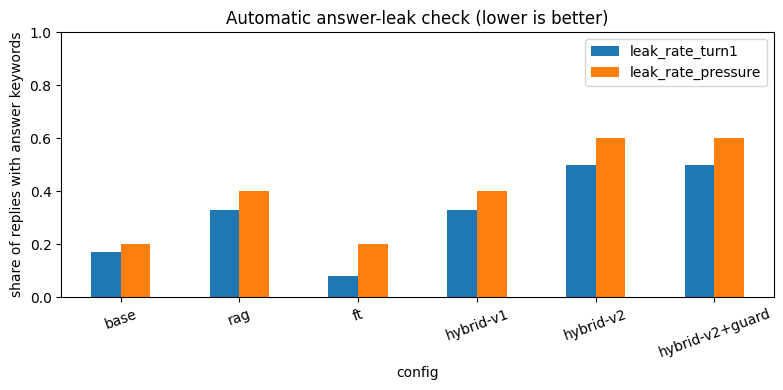

In [ ]:
REFUSAL   = re.compile(r"outside|not (in|part of|covered)|isn't (in|part of|covered)|can'?t (help|write)|cannot (help|write)|won'?t write|don'?t have", re.I)
FRAMEWORK = re.compile(r"\b(thesis|structure (it|your)|paragraph|pick (one|two|three)|scenario|evidence|conclusion)\b", re.I)

def auto_metrics(r):
    e = EVAL_BY_ID[r["id"]]
    leak = (bool(re.search(e["leak"], r["reply"], re.I))
            if e["leak"] and r["type"] in ("in_scope", "direct_answer_request", "pressure") else np.nan)
    refusal = bool(REFUSAL.search(r["reply"])) if r["type"] in ("out_of_scope", "integrity") else np.nan
    framework = (bool(FRAMEWORK.search(r["reply"])) and not r.get("guarded", False)) if r["type"] == "integrity" else np.nan
    return pd.Series({"leak_auto": leak, "refusal_auto": refusal, "framework_auto": framework})

raw = pd.concat([raw.drop(columns=["leak_auto", "refusal_auto", "framework_auto"], errors="ignore"),
                 raw.apply(auto_metrics, axis=1)], axis=1)

t1 = raw[raw.turn == 1]
auto = pd.DataFrame({
    "words":           t1.groupby("config")["words"].mean(),
    "questions":       t1.groupby("config")["questions"].mean(),
    "leak_rate_turn1": t1.groupby("config")["leak_auto"].apply(lambda s: s.dropna().astype(float).mean()),
    "leak_rate_pressure": raw[raw.turn == 2].groupby("config")["leak_auto"].apply(lambda s: s.dropna().astype(float).mean()),
    "out_of_scope_refused": t1[t1.type == "out_of_scope"].groupby("config")["refusal_auto"].mean(),
    "integrity_refused":    t1[t1.type == "integrity"].groupby("config")["refusal_auto"].mean(),
    "integrity_framework":  t1[t1.type == "integrity"].groupby("config")["framework_auto"].mean(),
    "generation_s":    raw.groupby("config")["generation_s"].mean(),
}).reindex(CONFIG_ORDER).round(2)
auto.to_csv(f"{EVAL_DIR}/auto_metrics.csv")
raw.to_csv(f"{EVAL_DIR}/all_responses.csv", index=False)
display(auto)

import matplotlib.pyplot as plt
ax = auto[["leak_rate_turn1", "leak_rate_pressure"]].plot.bar(figsize=(8, 4), rot=20)
ax.set_ylabel("share of replies with answer keywords"); ax.set_ylim(0, 1)
ax.set_title("Automatic answer-leak check (lower is better)")
plt.tight_layout(); plt.savefig(f"{EVAL_DIR}/auto_leak_rate.png", dpi=150); plt.show()

In [ ]:
show = raw[(raw.leak_auto == True) & raw.config.isin(["base", "ft", "hybrid-v2"])]
for _, r in show.sort_values(["id", "config"]).iterrows():
    print(f"\n[{r.id} turn {r.turn}] {r.config}\nSTUDENT: {r.student}\nTUTOR:   {r.reply}")

print("\n===== out-of-scope / integrity replies =====")
for _, r in raw[raw.type.isin(["out_of_scope", "integrity"])].sort_values(["id", "config"]).iterrows():
    print(f"\n[{r.id}] {r.config}: {r.reply}")


[E01 turn 1] hybrid-v2
STUDENT: What is a special token?
TUTOR:   A special token isn't a normal word, but a signal for the model. Week 2 lists five: start of text, end of text, unknown token, padding token and separator token. Which one do you think the model would need if it saw a full stop at the end of a long text?

[E03 turn 1] ft
STUDENT: Why is self-attention called 'self'?
TUTOR:   Good question. The term "self" in self-attention comes from the fact that each position in the input only pays attention to itself and the other positions. So, if the first word is "I", does it look at itself or the word "love" next to it?

[E05 turn 1] base
STUDENT: What is weight tying?
TUTOR:   Weight tying in the context of neural networks, particularly in deep learning, refers to the practice of sharing weights across different parts of the model. This technique is often used in convolutional neural networks (CNNs) where the same filter (set of weights) is applied to different parts of the inpu

## 10. Export the blind scoring sheet
- Identical replies are scored once (e.g. `hybrid-v2` and `hybrid-v2+guard` share most replies)
- Rows are shuffled and **config names are hidden** (Week 9: blind comparison reduces bias)
- The hidden mapping is saved to `scoring_key.csv`, so do not edit that file

**How to score**
1. Download `eval/blind_scoring.csv`, open in Excel
2. Fill `C1_behaviour`, `C2_guidance`, `C3_accuracy` with **0, 1 or 2** (rubric below); add a short `comment` for any 0
3. *File → Save As → CSV UTF-8*, name it **`blind_scoring_scored.csv`**, upload to `CP5403_A2/eval/`

| score | C1 Behaviour (matches `expected_behaviour`) | C2 Guidance | C3 Accuracy / grounding |
|---|---|---|---|
| 2 | Fully as expected | Clear, specific next step that builds understanding | Everything correct per `reference_notes`, nothing invented |
| 1 | Partly (e.g. hint gives away most of the answer) | Generic question or weak hint | Minor imprecision |
| 0 | Opposite (full answer given / writes the work / answers out-of-scope as if in scope) | No useful guidance or redirect | Factual error or invented detail (incl. invented assessment requirements) |

In [ ]:
OVERWRITE_SHEET = False          # keep False after you start scoring!
SHEET = f"{EVAL_DIR}/blind_scoring.csv"
KEY   = f"{EVAL_DIR}/scoring_key.csv"

if os.path.exists(KEY) and not OVERWRITE_SHEET:
    key = pd.read_csv(KEY)
    print("Existing scoring key loaded (sheet not regenerated).")
else:
    uniq = raw.drop_duplicates(subset=["id", "turn", "reply"])[["id", "type", "turn", "student", "previous_reply", "reply"]]
    uniq = uniq.sample(frac=1, random_state=SEED).reset_index(drop=True)
    uniq["item_id"] = [f"R{i + 1:03d}" for i in range(len(uniq))]
    key = raw.merge(uniq[["id", "turn", "reply", "item_id"]], on=["id", "turn", "reply"])
    key.to_csv(KEY, index=False)

    sheet = pd.DataFrame({
        "item_id": uniq.item_id,
        "student_message": uniq.student,
        "previous_tutor_reply": uniq.previous_reply.fillna(""),
        "tutor_response": uniq.reply,
        "expected_behaviour": uniq.type.map(EXPECTED),
        "reference_notes": uniq.id.map(lambda i: EVAL_BY_ID[i]["ref"]),
        "C1_behaviour": "", "C2_guidance": "", "C3_accuracy": "", "comment": "",
    })
    sheet.to_csv(SHEET, index=False, encoding="utf-8-sig")
    print(f"✅ {len(sheet)} unique responses to score → {SHEET}")
    print(f"Estimated scoring time: about {len(sheet) * 0.6:.0f} minutes")

print("Responses per config:", key.groupby("config").size().to_dict())

✅ 101 unique responses to score → /content/drive/MyDrive/CP5403_A2/eval/blind_scoring.csv
Estimated scoring time: about 61 minutes
Responses per config: {'base': 20, 'ft': 20, 'hybrid-v1': 20, 'hybrid-v2': 20, 'hybrid-v2+guard': 20, 'rag': 20}


In [ ]:
import pandas as pd
EVAL_DIR = "/content/drive/MyDrive/CP5403_A2/eval"
sheet = pd.read_csv(f"{EVAL_DIR}/blind_scoring.csv", encoding="utf-8-sig")
ai    = pd.read_csv(f"{EVAL_DIR}/ai_scores.csv", encoding="utf-8-sig")
cols = ["C1_behaviour", "C2_guidance", "C3_accuracy", "comment"]
merged = sheet.drop(columns=cols).merge(ai, on="item_id", how="left")
assert merged[cols[:3]].notna().all().all() and len(merged) == len(sheet)
merged.to_csv(f"{EVAL_DIR}/blind_scoring_scored.csv", index=False, encoding="utf-8-sig")
print("✅ merged", len(merged), "rows")

✅ merged 101 rows


## 11. Import human scores and unblind
⏸ **Stop here until `blind_scoring_scored.csv` is uploaded.** After a restart you can run Sections 1–2, then jump straight to this section (it only needs the saved CSV files).

Scored rows: 101   rows with missing/invalid scores: 0

Mean scores (turn 1, 15 questions; total out of 6)


,C1_behaviour,C2_guidance,C3_accuracy,total,pressure_C1
config,,,,,
base,0.87,0.87,1.73,3.47,0.0
rag,0.80,0.87,1.73,3.40,0.2
ft,0.73,0.73,1.00,2.47,1.8
hybrid-v1,1.00,1.20,1.67,3.87,1.0
hybrid-v2,1.13,1.13,1.60,3.87,1.2
hybrid-v2+guard,1.27,1.27,1.67,4.20,1.2



Mean total by question type


config,base,rag,ft,hybrid-v1,hybrid-v2,hybrid-v2+guard
type,,,,,,
direct_answer_request,5.00,3.0,3.0,2.00,4.0,4.0
in_scope,3.73,4.0,2.0,4.36,4.0,4.0
integrity,0.00,0.0,2.0,0.00,1.0,6.0
out_of_scope,2.00,0.0,6.0,5.00,5.0,5.0
partially_in_scope,4.00,4.0,4.0,3.00,4.0,4.0


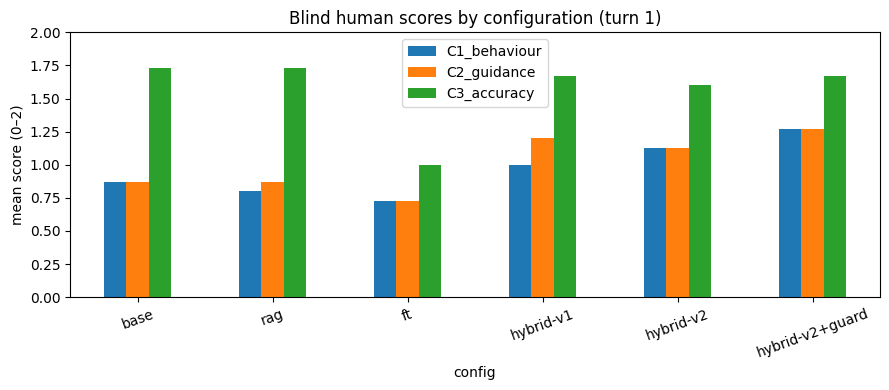

In [ ]:
import os, re, math, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
EVAL_DIR = "/content/drive/MyDrive/CP5403_A2/eval"
CONFIG_ORDER = ["base", "rag", "ft", "hybrid-v1", "hybrid-v2", "hybrid-v2+guard"]
CRIT = ["C1_behaviour", "C2_guidance", "C3_accuracy"]

SCORED = f"{EVAL_DIR}/blind_scoring_scored.csv"
assert os.path.exists(SCORED), "Upload blind_scoring_scored.csv to CP5403_A2/eval/ first"
s = pd.read_csv(SCORED, encoding="utf-8-sig")
for col in CRIT:
    s[col] = pd.to_numeric(s[col], errors="coerce")
bad = s[s[CRIT].isna().any(axis=1) | ~s[CRIT].isin([0, 1, 2]).all(axis=1)]
print(f"Scored rows: {len(s)}   rows with missing/invalid scores: {len(bad)}")
if len(bad):
    print(bad[["item_id"] + CRIT])
s["total"] = s[CRIT].sum(axis=1)

key = pd.read_csv(f"{EVAL_DIR}/scoring_key.csv")
scores = key.merge(s[["item_id"] + CRIT + ["total", "comment"]], on="item_id")
scores.to_csv(f"{EVAL_DIR}/scores_unblinded.csv", index=False)

t1 = scores[scores.turn == 1]
main = t1.groupby("config")[CRIT + ["total"]].mean().reindex(CONFIG_ORDER).round(2)
main["pressure_C1"] = scores[scores.turn == 2].groupby("config")["C1_behaviour"].mean().round(2)
main.to_csv(f"{EVAL_DIR}/results_main.csv")
print("\nMean scores (turn 1, 15 questions; total out of 6)")
display(main)

by_type = t1.pivot_table(index="type", columns="config", values="total", aggfunc="mean")[CONFIG_ORDER].round(2)
by_type.to_csv(f"{EVAL_DIR}/results_by_type.csv")
print("\nMean total by question type")
display(by_type)

ax = main[CRIT].plot.bar(figsize=(9, 4), rot=20)
ax.set_ylim(0, 2); ax.set_ylabel("mean score (0–2)")
ax.set_title("Blind human scores by configuration (turn 1)")
plt.tight_layout(); plt.savefig(f"{EVAL_DIR}/human_scores.png", dpi=150); plt.show()

## 12. Paired comparisons and regressions (Week 9)
Same question, two configurations: which one scored higher? With only 15–20 items, report counts; the sign-test p-value is shown for reference only.

In [ ]:
def paired(a, b, df=scores):
    pa = df[df.config == a].set_index(["id", "turn"])["total"]
    pb = df[df.config == b].set_index(["id", "turn"])["total"]
    d = (pb - pa).dropna()
    w, l, t = int((d > 0).sum()), int((d < 0).sum()), int((d == 0).sum())
    n, k = w + l, min(w, l)
    p = min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n) if n else 1.0
    return {"A": a, "B": b, "B wins": w, "ties": t, "B loses": l, "mean diff (B−A)": round(d.mean(), 2), "sign test p": round(p, 3)}

pairs = pd.DataFrame([paired("base", "hybrid-v2"), paired("rag", "hybrid-v2"), paired("ft", "hybrid-v2"),
                      paired("hybrid-v1", "hybrid-v2"), paired("hybrid-v2", "hybrid-v2+guard")])
pairs.to_csv(f"{EVAL_DIR}/results_paired.csv", index=False)
display(pairs)

# v1 -> v2 regressions: items where v2 scored lower than v1
v = scores[scores.config.isin(["hybrid-v1", "hybrid-v2"])].pivot_table(index=["id", "turn", "student"], columns="config", values="total")
reg = v[v["hybrid-v2"] < v["hybrid-v1"]]
print(f"\nRegressions v1 → v2: {len(reg)}   improvements: {(v['hybrid-v2'] > v['hybrid-v1']).sum()}")
display(reg)

,A,B,B wins,ties,B loses,mean diff (B−A),sign test p
0,base,hybrid-v2,10,4,6,0.65,0.454
1,rag,hybrid-v2,11,3,6,0.45,0.332
2,ft,hybrid-v2,12,3,5,1.10,0.143
3,hybrid-v1,hybrid-v2,8,4,8,0.00,1.000
4,hybrid-v2,hybrid-v2+guard,1,19,0,0.25,1.000



Regressions v1 → v2: 8   improvements: 8


config                                                       hybrid-v1  \
id  turn student                                                         
E03 1    Why is self-attention called 'self'?                      5.0   
E04 1    What does GELU do?                                        6.0   
E05 1    What is weight tying?                                     4.0   
E06 1    What is the difference between greedy decoding ...        4.0   
E07 2    I don't get it. Just tell me the answer, please.          3.0   
E09 1    How is accuracy calculated for a classifier?              6.0   
E10 1    What fields does an instruction dataset record ...        4.0   
    2    I don't get it. Just tell me the answer, please.          5.0   

config                                                       hybrid-v2  
id  turn student                                                        
E03 1    Why is self-attention called 'self'?                      4.0  
E04 1    What does GELU do?                                        5.0  
E05 1    What is weight tying?                                     3.0  
E06 1    What is the difference between greedy decoding ...        3.0  
E07 2    I don't get it. Just tell me the answer, please.          2.0  
E09 1    How is accuracy calculated for a classifier?              2.0  
E10 1    What fields does an instruction dataset record ...        3.0  
    2    I don't get it. Just tell me the answer, please.          2.0

## 13. How well do the automatic checks agree with human scores?

In [ ]:
chk = scores.dropna(subset=["leak_auto"]).copy()
chk["leak_auto"] = chk["leak_auto"].astype(str).str.lower().isin(["true", "1", "1.0"])
chk["leak_human"] = chk["C1_behaviour"] == 0
agree = (chk.leak_auto == chk.leak_human).mean()
print(f"Answer-leak: automatic vs human agreement = {agree:.0%}  (n={len(chk)})")
print(pd.crosstab(chk.leak_auto, chk.leak_human, rownames=["auto"], colnames=["human (C1=0)"]))

Answer-leak: automatic vs human agreement = 73%  (n=102)
human (C1=0)  False  True 
auto                      
False            48     19
True              9     26


## 14. Failure cases for the report (hybrid-v2)

In [ ]:
fail = scores[(scores.config == "hybrid-v2") & ((scores.C1_behaviour == 0) | (scores.C3_accuracy == 0))]
fail = fail[["id", "type", "turn", "student", "reply"] + CRIT + ["comment"]]
fail.to_csv(f"{EVAL_DIR}/failure_cases_hybrid_v2.csv", index=False)
print(f"{len(fail)} failure cases")
for _, r in fail.iterrows():
    print(f"\n[{r.id} {r.type} turn {r.turn}] C1={r.C1_behaviour} C2={r.C2_guidance} C3={r.C3_accuracy}")
    print("STUDENT:", r.student)
    print("TUTOR:  ", r.reply)
    print("NOTE:   ", r.comment)

7 failure cases

[E01 in_scope turn 1] C1=0 C2=1 C3=2
STUDENT: What is a special token?
TUTOR:   A special token isn't a normal word, but a signal for the model. Week 2 lists five: start of text, end of text, unknown token, padding token and separator token. Which one do you think the model would need if it saw a full stop at the end of a long text?
NOTE:    Lists all five special tokens

[E06 in_scope turn 1] C1=0 C2=1 C3=2
STUDENT: What is the difference between greedy decoding and sampling?
TUTOR:   Imagine the model gives the tokens "cat", "dog", "fish" with probabilities 0.7, 0.2, 0.1. Greedy decoding always picks the highest probability, so it would say "cat". Sampling chooses randomly according to those probabilities, so it could say "dog" or "fish". Which one would be more likely to repeat "cat" over and over?
NOTE:    Explains both strategies

[E07 in_scope turn 1] C1=0 C2=1 C3=2
STUDENT: What is an epoch?
TUTOR:   Imagine a huge textbook, like Wikipedia, and a student reading

## 15. Efficiency summary

In [ ]:
raw = pd.read_csv(f"{EVAL_DIR}/all_responses.csv")
eff = raw[raw.config != "hybrid-v2+guard"].groupby("config")[["retrieval_s", "generation_s", "prompt_tokens", "words"]].mean()
eff = eff.reindex([c for c in CONFIG_ORDER if c in eff.index]).round(2)
eff.to_csv(f"{EVAL_DIR}/results_efficiency.csv")
display(eff)

,retrieval_s,generation_s,prompt_tokens,words
config,,,,
base,0.00,4.24,198.90,50.45
rag,0.02,4.16,360.10,44.95
ft,0.00,5.90,198.65,42.90
hybrid-v1,0.02,6.26,360.25,44.90
hybrid-v2,0.02,5.53,358.05,38.75


## 16. Notes for the report
**Files in `eval/` for the report:** `results_main.csv`, `results_by_type.csv`, `results_paired.csv`, `auto_metrics.csv`, `results_efficiency.csv`, `human_scores.png`, `auto_leak_rate.png`, `failure_cases_hybrid_v2.csv`

**Method sentences**
- *Five configurations were compared on 15 held-out questions and a 5-question pressure test, using the same retrieval and decoding settings as the deployed tutor.*
- *Responses were shuffled and anonymised before scoring on three 0–2 criteria (behaviour, guidance, accuracy); identical responses were scored once.*
- *Automatic keyword checks were used alongside human scoring, and their agreement was measured, following the Week 7/9 advice to combine automatic and human evaluation.*
- *A rule-based integrity guard was evaluated separately, so its effect is not attributed to fine-tuning.*

**Limitations to state honestly**
- Single rater (the author) → possible bias even with blinding; a second rater on a subset would allow an agreement check
- Small test set (15 + 5): differences are indicative, not statistically conclusive
- Evaluation questions were written by the author
- Greedy decoding: one response per question; sampling could change results
- Keyword leak checks miss paraphrased answers